# Studio 2 — Algorithm analysis

Run all cells from this folder with NumPy, pandas, matplotlib and Jupyter installed. The benchmark records measured timings and checks every result against `sorted()`.

In [1]:
def alg1(data):
    data = list(data)
    changes = True
    while changes:
        changes = False
        for i in range(len(data) - 1):
            if data[i + 1] < data[i]:
                data[i], data[i + 1] = data[i + 1], data[i]
                changes = True
    return data


def alg2(data):
    if len(data) <= 1:
        return data
    else:
        split = len(data) // 2
        left = iter(alg2(data[:split]))
        right = iter(alg2(data[split:]))
        result = []
        left_top = next(left)
        right_top = next(right)
        while True:
            if left_top < right_top:
                result.append(left_top)
                try:
                    left_top = next(left)
                except StopIteration:
                    return result + [right_top] + list(right)
            else:
                result.append(right_top)
                try:
                    right_top = next(right)
                except StopIteration:
                    return result + [left_top] + list(left)

In [2]:
import numpy as np

# Assignment-provided generators (Studio 2, page 4).
def data1(n, sigma=10, rho=28, beta=8 / 3, dt=0.01, x=1, y=1, z=1):
    state = np.array([x, y, z], dtype=float)
    result = []
    for _ in range(n):
        x, y, z = state
        state += dt * np.array(
            [sigma * (y - x), x * (rho - z) - y, x * y - beta * z]
        )
        result.append(float(state[0] + 30))
    return result


def data2(n):
    return list(range(n))


def data3(n):
    return list(range(n, 0, -1))

In [3]:
n = 8

test_cases = [
    ("data1", data1(n)),
    ("data2", data2(n)),
    ("data3", data3(n)),
]

for case_name, test_input in test_cases:
    output1 = alg1(test_input.copy())
    output2 = alg2(test_input.copy())
    expected = sorted(test_input)

    print(f"Case: {case_name}")
    print("Input:   ", test_input)
    print("alg1:    ", output1)
    print("alg2:    ", output2)
    print("Both correct:", output1 == expected and output2 == expected)
    print("-" * 50)

Case: data1
Input:    [31.0, 31.026, 31.07515666666667, 31.1456131764, 31.236317170692352, 31.346883543428103, 31.477492347868477, 31.628814213217787]
alg1:     [31.0, 31.026, 31.07515666666667, 31.1456131764, 31.236317170692352, 31.346883543428103, 31.477492347868477, 31.628814213217787]
alg2:     [31.0, 31.026, 31.07515666666667, 31.1456131764, 31.236317170692352, 31.346883543428103, 31.477492347868477, 31.628814213217787]
Both correct: True
--------------------------------------------------
Case: data2
Input:    [0, 1, 2, 3, 4, 5, 6, 7]
alg1:     [0, 1, 2, 3, 4, 5, 6, 7]
alg2:     [0, 1, 2, 3, 4, 5, 6, 7]
Both correct: True
--------------------------------------------------
Case: data3
Input:    [8, 7, 6, 5, 4, 3, 2, 1]
alg1:     [1, 2, 3, 4, 5, 6, 7, 8]
alg2:     [1, 2, 3, 4, 5, 6, 7, 8]
Both correct: True
--------------------------------------------------


In [4]:
# Known cases independently exercise emptiness, duplicates and negative values.
known_cases = [[], [7], [3, 1, 3, -2, 0], [5, 4, 3, 2, 1], [1, 2, 3]]
for values in known_cases:
    for algorithm in (alg1, alg2):
        assert algorithm(values.copy()) == sorted(values)
print("Passed 10 known-case sorting checks.")

# Check the small-data transition visible in the expanded benchmark.
for n, expected_ordered in [(10, True), (18, True), (32, True), (56, False), (100, False)]:
    values = data1(n)
    ordered = values == sorted(values)
    assert ordered == expected_ordered
    print(f"data1 n={n}: already sorted = {ordered}")


Passed 10 known-case sorting checks.
data1 n=10: already sorted = True
data1 n=18: already sorted = True
data1 n=32: already sorted = True
data1 n=56: already sorted = False
data1 n=100: already sorted = False


Completed data1, n=10
Completed data1, n=18
Completed data1, n=32
Completed data1, n=56
Completed data1, n=100
Completed data1, n=178
Completed data1, n=316
Completed data1, n=562
Completed data1, n=1000
Completed data1, n=1778
Completed data1, n=3162
Completed data1, n=5623
Completed data1, n=10000
Completed data2, n=10
Completed data2, n=18
Completed data2, n=32
Completed data2, n=56
Completed data2, n=100
Completed data2, n=178
Completed data2, n=316
Completed data2, n=562
Completed data2, n=1000
Completed data2, n=1778
Completed data2, n=3162
Completed data2, n=5623
Completed data2, n=10000
Completed data3, n=10
Completed data3, n=18
Completed data3, n=32
Completed data3, n=56
Completed data3, n=100
Completed data3, n=178
Completed data3, n=316
Completed data3, n=562
Completed data3, n=1000
Completed data3, n=1778
Completed data3, n=3162
Completed data3, n=5623
Completed data3, n=10000
Measured run completed: 2026-11-08T02:07:07.946051+00:00
Python 3.13.5; macOS-14.6-arm64-arm-64bi

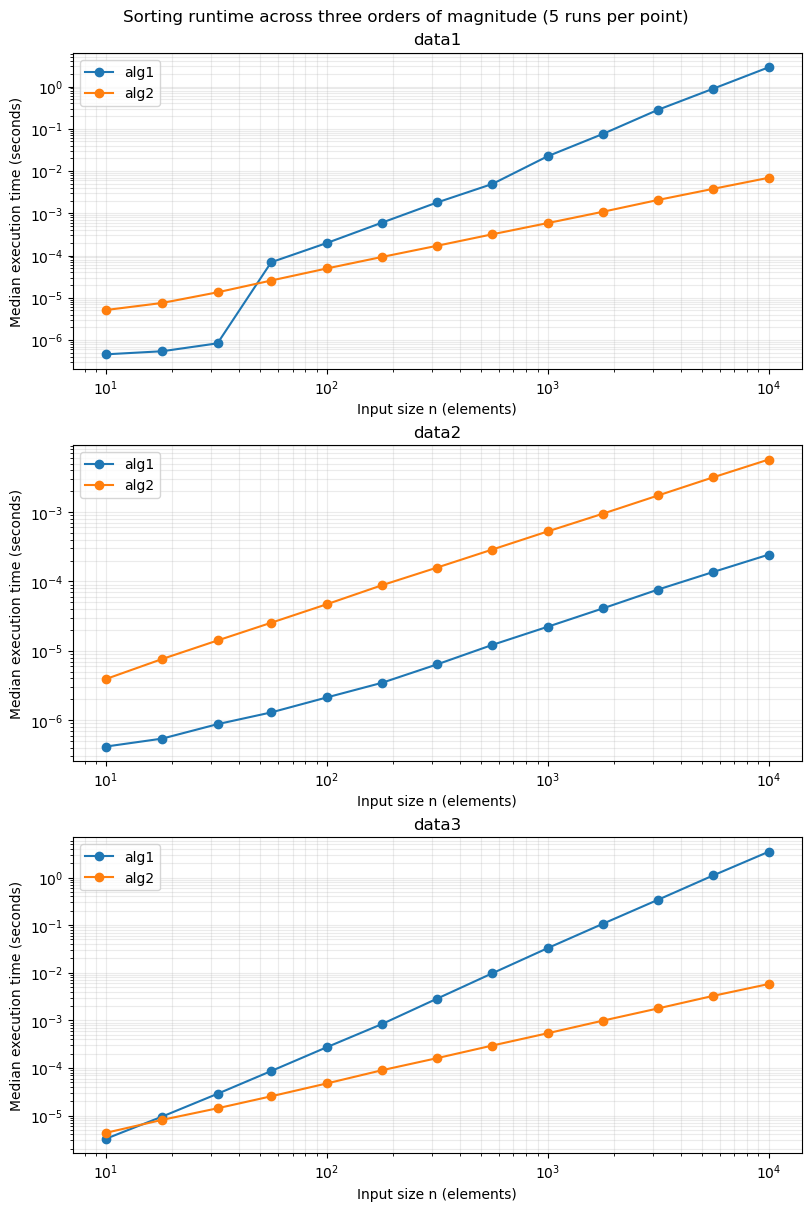

algorithm              alg1      alg2
dataset n                            
data1   10     4.580070e-07  0.000005
        18     5.420006e-07  0.000008
        32     8.339994e-07  0.000013
        56     6.925000e-05  0.000026
        100    1.976670e-04  0.000049
        178    6.011660e-04  0.000093
        316    1.803958e-03  0.000170
        562    4.942500e-03  0.000318
        1000   2.238342e-02  0.000586
        1778   7.551762e-02  0.001085
        3162   2.820723e-01  0.002068
        5623   8.909027e-01  0.003794
        10000  2.845861e+00  0.006907
data2   10     4.159956e-07  0.000004
        18     5.420006e-07  0.000008
        32     8.749994e-07  0.000014
        56     1.291999e-06  0.000025
        100    2.125002e-06  0.000047
        178    3.458001e-06  0.000088
        316    6.374998e-06  0.000159
        562    1.216700e-05  0.000289
        1000   2.220900e-05  0.000526
        1778   4.087500e-05  0.000949
        3162   7.645800e-05  0.001737
        5623   1.370420e-04  0.003177
        10000  2.432090e-04  0.005721
data3   10     3.249996e-06  0.000004
        18     9.541996e-06  0.000008
        32     2.862500e-05  0.000014
        56     8.612500e-05  0.000025
        100    2.726250e-04  0.000047
        178    8.385410e-04  0.000090
        316    2.862292e-03  0.000161
        562    9.764291e-03  0.000296
        1000   3.289058e-02  0.000536
        1778   1.068074e-01  0.000985
        3162   3.420448e-01  0.001781
        5623   1.111470e+00  0.003275
        10000  3.476171e+00  0.005787

,dataset,algorithm,full_range,large_n
0,data1,alg1,2.377245,2.112111
1,data1,alg2,1.069114,1.074453
2,data2,alg1,0.956236,1.041703
3,data2,alg2,1.051165,1.038858
4,data3,alg1,2.031046,2.026112
5,data3,alg2,1.046446,1.035508


In [5]:
import time
import platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 10 to 10,000 covers three full orders of magnitude.
sizes = np.unique(np.rint(np.logspace(1, 4, num=13)).astype(int))
repeats = 5
generators = {"data1": data1, "data2": data2, "data3": data3}
algorithms = {"alg1": alg1, "alg2": alg2}
records = []

for data_name, generator in generators.items():
    for n in sizes:
        test_data = generator(int(n))
        expected = sorted(test_data)
        for algorithm in algorithms.values():
            assert algorithm(test_data.copy()) == expected
        for repeat in range(repeats):
            order = list(algorithms.items())
            if repeat % 2:
                order.reverse()
            for algorithm_name, algorithm in order:
                input_copy = test_data.copy()
                start = time.perf_counter()
                result = algorithm(input_copy)
                elapsed = time.perf_counter() - start
                assert result == expected
                records.append({"dataset": data_name, "n": int(n),
                                "algorithm": algorithm_name, "repeat": repeat + 1,
                                "seconds": elapsed})
        print(f"Completed {data_name}, n={n}", flush=True)

raw = pd.DataFrame(records)
raw.to_csv("benchmark-runs.csv", index=False)
results = (raw.groupby(["dataset", "n", "algorithm"], as_index=False)["seconds"]
           .median().rename(columns={"seconds": "median_seconds"}))
results.to_csv("benchmark-medians.csv", index=False)

# Report full-range and large-n slopes separately: small n can hide growth.
slope_records = []
for (data_name, algorithm_name), subset in results.groupby(["dataset", "algorithm"]):
    row = {"dataset": data_name, "algorithm": algorithm_name}
    for label, lower in [("full_range", 10), ("large_n", 1000)]:
        selected = subset.loc[subset["n"] >= lower]
        row[label] = np.polyfit(np.log10(selected["n"]),
                               np.log10(selected["median_seconds"]), 1)[0]
    slope_records.append(row)
slopes = pd.DataFrame(slope_records)
slopes.to_csv("benchmark-slopes.csv", index=False)

fig, axes = plt.subplots(3, 1, figsize=(8, 12), layout="constrained")
for ax, data_name in zip(axes, generators):
    for algorithm_name in algorithms:
        subset = results.loc[(results["dataset"] == data_name)
                             & (results["algorithm"] == algorithm_name)].sort_values("n")
        ax.loglog(subset["n"], subset["median_seconds"], marker="o", label=algorithm_name)
    ax.set(title=data_name, xlabel="Input size n (elements)",
           ylabel="Median execution time (seconds)")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend()
fig.suptitle("Sorting runtime across three orders of magnitude (5 runs per point)")
fig.savefig("algorithm-runtime-comparison.png", dpi=150)
plt.show()

timing_table = results.pivot(index=["dataset", "n"], columns="algorithm", values="median_seconds")
metadata = (f"Measured run completed: {datetime.now(timezone.utc).isoformat()}\n"
            f"Python {platform.python_version()}; {platform.platform()}\n"
            f"n: {sizes.tolist()}; repeats: {repeats}; timer: perf_counter\n"
            "Generation, external copying, reference sorting and assertions excluded from timing.\n"
            "Raw trials: benchmark-runs.csv; all 390 timed results matched sorted().\n")
with open("benchmark-results.txt", "w") as output:
    report = (metadata + "\nMedian seconds\n" + timing_table.to_string(float_format=lambda x: f"{x:.9g}")
              + "\n\nLog-log slopes: full range 10–10000; large n 1000–10000\n"
              + slopes.to_string(index=False))
    output.write("\n".join(line.rstrip() for line in report.splitlines()) + "\n")
print(metadata)
display(timing_table)
display(slopes)